# **OPT-CNN-B**

In [1]:
# ── Librerías ────────────────────────────────────────────────────────────────────
import os
import gc
import random
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from optuna.trial import TrialState
from tqdm.auto import tqdm as _tqdm
import pynvml
import time
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

I0000 00:00:1786737130.548768 1261933 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# Verificar GPU
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    tf.config.set_logical_device_configuration(
        gpus[0],
        [tf.config.LogicalDeviceConfiguration(memory_limit=15360)]  # Límite de 15 GB
    )
    print(f'GPU encontrada: {gpus[0].name} (límite 15GB)')
else:
    print('No se encontró GPU, corriendo en CPU')

GPU encontrada: /physical_device:GPU:0 (límite 15GB)


-------------
## **Búsqueda de Hiperparámetros**
---------------

In [3]:
# ── Rutas ────────────────────────────────────────────────────────────────────
REPO_ROOT   = Path(subprocess.run(['git', 'rev-parse', '--show-toplevel'], capture_output=True, text=True).stdout.strip())
DATA_PATH   = Path.home() / 'pfc' / 'Dataset Sintetico 352x192'
MODELS_PATH = REPO_ROOT / 'Códigos' / 'Modelos' / 'Fase 1' / 'CNN-B'
MODELS_PATH.mkdir(parents=True, exist_ok=True)

In [4]:
# ── Experimento ────────────────────────────────────────────────────────────
EXPERIMENT_NAME  = 'OPT-CNN-B'
ARQUITECTURA     = 'CNN-B'
DATASET       = 'Sintético'

# ── Imagen ────────────────────────────────────────────────────────────────────
IMG_HEIGHT    = 192
IMG_WIDTH     = 352
NUM_CLASSES   = 5
CLASSES       = ['CD', 'HYP', 'MI', 'NORM', 'STTC']
CHANNELS      = 1

# ── Entrenamiento ─────────────────────────────────────────────────────────────
LOSS_FUNCTION  = 'sparse_categorical_crossentropy'
N_TRIALS       = 30
EPOCH_MAX      = 100
SEED           = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED']         = str(SEED)
os.environ['TF_DETERMINISTIC_OPS']   = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
tf.config.experimental.enable_op_determinism()

# ── Callbacks ─────────────────────────────────────────────────────────────
# Early Stopping
ES_PATIENCE  = 8
ES_MIN_DELTA = 0.0001
METRIC       = 'val_loss'
DIRECTION    = 'minimize'
# Pruner
N_STARTUP_TRIALS    = 8
N_WARMUP_STEPS      = 10
INTERVAL_STEPS      = 1
N_MIN_TRIALS_PRUNER = 3
# RLR
RLR_FACTOR    = 0.5
RLR_PATIENCE  = 5
RLR_MIN_DELTA = 0.0001
RLR_MIN_LR    = 1e-7

# ── Espacios de búsqueda ──────────────────────────────────────────────────────
NUM_BLOCKS_RANGE  = (4, 5)
BASE_FILTERS_OPTS = [32, 64]
DENSE_UNITS       = 128
DROPOUT_RANGE     = (0.1, 0.4)
LR_RANGE          = (1e-4, 1e-3)
BATCH_SIZE        = 32
OPTIMIZER         = 'Adam'

### **Arquitectura**

In [5]:
def build_cnn_b(num_blocks, base_filters, dense_units, dropout,
                input_shape=(192, 352, 1), num_classes=5):
    inputs = tf.keras.Input(shape=input_shape)
    x = inputs

    for i in range(num_blocks):
        filters = base_filters * (2 ** i)
        drop_i  = min(dropout + i * 0.05, 0.4)

        residual = x

        x = layers.Conv2D(filters, (3, 3), padding='same')(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)

        x = layers.Conv2D(filters, (3, 3), padding='same')(x)
        x = layers.BatchNormalization()(x)

        if residual.shape[-1] != filters:
            residual = layers.Conv2D(filters, (1, 1), padding='same')(residual)
            residual = layers.BatchNormalization()(residual)

        x = layers.Add()([x, residual])
        x = layers.ReLU()(x)

        x = layers.MaxPooling2D((2, 2))(x)
        x = layers.Dropout(drop_i)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense_units, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(num_classes, activation='softmax')(x)

    return tf.keras.Model(inputs=inputs, outputs=x, name='CNN_B')

### **Carga de Datos**

In [6]:
AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(directory, shuffle):
    ds = tf.keras.utils.image_dataset_from_directory(
        directory,
        image_size  = (IMG_HEIGHT, IMG_WIDTH),
        color_mode  = 'grayscale',
        class_names = CLASSES,
        batch_size  = BATCH_SIZE,
        shuffle     = shuffle,
        seed        = SEED if shuffle else None,
        label_mode  = 'int',
    )
    return (
        ds.map(lambda x, y: (x / 255.0, y), num_parallel_calls=AUTOTUNE)
          .prefetch(AUTOTUNE)
    )

# NOTA: train_data y val_data se instancian dentro de objective()
# para garantizar que cada trial empiece con el mismo estado del dataset.
test_data = make_dataset(DATA_PATH / 'test', shuffle=False)

print('Clases:', CLASSES)

Found 10258 files belonging to 5 classes.
Clases: ['CD', 'HYP', 'MI', 'NORM', 'STTC']


I0000 00:00:1786737336.053545 1261933 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15360 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:09:00.0, compute capability: 7.5


### **Estudio de Optuna**

In [7]:
class _DuplicateParamsError(Exception):
    pass


class OptunaPruningCallback(tf.keras.callbacks.Callback):
    def __init__(self, trial, monitor='val_loss'):
        super().__init__()
        self.trial   = trial
        self.monitor = monitor

    def on_epoch_end(self, epoch, logs=None):
        value = logs.get(self.monitor)
        if value is not None:
            self.trial.report(value, epoch)
        if self.trial.should_prune():
            raise optuna.TrialPruned()


def objective(trial):
    # ── Sugerir hiperparámetros primero (antes de cargar datos) ──────────────
    num_blocks   = trial.suggest_int('num_blocks',           *NUM_BLOCKS_RANGE)
    base_filters = trial.suggest_categorical('base_filters', BASE_FILTERS_OPTS)
    dropout      = trial.suggest_float('dropout',            *DROPOUT_RANGE)
    lr           = trial.suggest_float('learning_rate',      *LR_RANGE, log=True)

    # ── Anti-duplicado ────────────────────────────────────────────────────────
    for past in trial.study.trials:
        if past.number == trial.number:
            continue
        if past.state != TrialState.COMPLETE:
            continue
        if past.params == trial.params:
            print(f'  [dup] Trial {trial.number} repite trial {past.number} — descartado')
            raise _DuplicateParamsError(f'Duplicado del trial {past.number}')
    # ─────────────────────────────────────────────────────────────────────────

    tf.keras.backend.clear_session()
    gc.collect()
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    train_data = make_dataset(DATA_PATH / 'train', shuffle=True)
    val_data   = make_dataset(DATA_PATH / 'val',   shuffle=False)

    model = build_cnn_b(
        num_blocks   = num_blocks,
        base_filters = base_filters,
        dense_units  = DENSE_UNITS,
        dropout      = dropout,
        input_shape  = (IMG_HEIGHT, IMG_WIDTH, CHANNELS),
        num_classes  = NUM_CLASSES,
    )
    model.compile(
        optimizer = tf.keras.optimizers.Adam(learning_rate=lr),
        loss      = LOSS_FUNCTION,
        metrics   = ['accuracy'],
    )

    history = model.fit(
        train_data,
        validation_data = val_data,
        epochs          = EPOCH_MAX,
        callbacks       = [
            EarlyStopping(
                monitor              = METRIC,
                patience             = ES_PATIENCE,
                min_delta            = ES_MIN_DELTA,
                restore_best_weights = True,
            ),
            ReduceLROnPlateau(
                monitor   = METRIC,
                factor    = RLR_FACTOR,
                patience  = RLR_PATIENCE,
                min_delta = RLR_MIN_DELTA,
                min_lr    = RLR_MIN_LR,
            ),
            OptunaPruningCallback(trial, monitor=METRIC),
        ],
        verbose = 0,
    )

    trial.set_user_attr('epochs_trained', len(history.history[METRIC]))
    return min(history.history[METRIC])

In [8]:
_db_path = MODELS_PATH / (EXPERIMENT_NAME + '.db')

study = optuna.create_study(
    direction      = DIRECTION,
    study_name     = EXPERIMENT_NAME,
    storage        = f'sqlite:///{_db_path}',
    load_if_exists = True,
    sampler        = optuna.samplers.TPESampler(seed=SEED),
    pruner         = optuna.pruners.MedianPruner(
        n_startup_trials = N_STARTUP_TRIALS,
        n_warmup_steps   = N_WARMUP_STEPS,
        n_min_trials     = N_MIN_TRIALS_PRUNER,
        interval_steps   = INTERVAL_STEPS,
    ),
)

# ── Marcar zombies como FAIL ──────────────────────────────────────────────────
_all_trials = study.trials
_zombies = [t for t in _all_trials if t.state == TrialState.RUNNING]
if _zombies:
    for t in _zombies:
        try:
            study._storage.set_trial_state_values(t._trial_id, TrialState.FAIL, {})
        except Exception:
            pass
    _all_trials = study.trials

# ── Reintentar último trial fallido (solo si no es un duplicado) ──────────────
_failed = [t for t in _all_trials if t.state == TrialState.FAIL and t.params]
if _failed:
    last_failed       = max(_failed, key=lambda t: t.number)
    last_done         = max((t.number for t in _all_trials if t.state in (TrialState.COMPLETE, TrialState.PRUNED)), default=-1)
    _completed_params = [t.params for t in _all_trials if t.state == TrialState.COMPLETE]
    if last_failed.number > last_done and last_failed.params not in _completed_params:
        print(f'  Trial {last_failed.number} fallido → reintento')
        study.enqueue_trial(last_failed.params)

# ── Trials restantes ──────────────────────────────────────────────────────────
n_completados = len([t for t in study.trials
                     if t.state in (TrialState.COMPLETE, TrialState.PRUNED)])
n_restantes   = max(0, N_TRIALS - n_completados)
print(f'Trials completados: {n_completados} — Trials restantes: {n_restantes}')

# ── Progress bar ──────────────────────────────────────────────────────────────
_pbar = _tqdm(total=N_TRIALS, initial=n_completados, desc='Optuna', unit='trial')

def _trial_callback(study, trial):
    n_done = len([t for t in study.trials
                  if t.state in (TrialState.COMPLETE, TrialState.PRUNED)])
    if trial.state == TrialState.COMPLETE:
        _pbar.update(1)
        best = study.best_trial
        _pbar.set_postfix({
            'mejor_trial': best.number,
            'mejor_loss':  f'{best.value:.4f}',
            'ultimo':      f'{trial.value:.4f}',
        })
        print(f'Trial {trial.number:>3} | val_loss={trial.value:.4f} | mejor={best.value:.4f} (t{best.number}) | {n_done}/{N_TRIALS}')
    elif trial.state == TrialState.PRUNED:
        _pbar.update(1)
        _pbar.set_postfix({'ultimo': 'podado'})
        print(f'Trial {trial.number:>3} | PODADO | {n_done}/{N_TRIALS}')
    elif trial.state == TrialState.FAIL:
        _pbar.set_postfix({'ultimo': 'FAILED'})
        print(f'Trial {trial.number:>3} | FAILED | {n_done}/{N_TRIALS}')

study.optimize(
    objective,
    n_trials          = n_restantes,
    show_progress_bar = False,
    gc_after_trial    = True,
    catch             = (tf.errors.ResourceExhaustedError, _DuplicateParamsError),
    callbacks         = [_trial_callback],
)
_pbar.close()

  Trial 19 fallido → reintento
Trials completados: 14 — Trials restantes: 16


Optuna:  47%|####6     | 14/30 [00:00<?, ?trial/s]

Found 46497 files belonging to 5 classes.
Found 11624 files belonging to 5 classes.


E0000 00:00:1786737352.921625 1261933 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CNN_B_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1786737354.822085 1262153 cuda_dnn.cc:461] Loaded cuDNN version 92200


Trial  20 | val_loss=0.5987 | mejor=0.5768 (t0) | 15/30
Found 46497 files belonging to 5 classes.
Found 11624 files belonging to 5 classes.


...

Trial  33 | val_loss=0.5827 | mejor=0.5768 (t0) | 28/30
Found 46497 files belonging to 5 classes.
Found 11624 files belonging to 5 classes.


E0000 00:00:1786861396.572220 1261933 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CNN_B_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


Trial  34 | val_loss=0.5725 | mejor=0.5725 (t34) | 29/30
Found 46497 files belonging to 5 classes.
Found 11624 files belonging to 5 classes.


E0000 00:00:1786875657.606439 1261933 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CNN_B_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


Trial  35 | PODADO | 30/30


In [9]:
# ── Cargar estudio ──────────────────────────────────────────────────────────────
study = optuna.load_study(
    study_name = EXPERIMENT_NAME,
    storage    = f'sqlite:///{_db_path}',
)
df_study = study.trials_dataframe()
display(df_study)

# ── Guardar csv ──────────────────────────────────────────────────────────────
df_clean = df_study[df_study['state'].isin(['COMPLETE', 'PRUNED'])].copy()
df_clean = df_clean.reset_index(drop=True)
df_clean.index = df_clean.index + 1
df_clean.index.name = 'trial'

param_cols = sorted([c for c in df_clean.columns if c.startswith('params_')])
cols_order = ['value', 'state', 'datetime_start', 'datetime_complete',
              'duration', 'user_attrs_epochs_trained'] + param_cols
df_clean = df_clean[[c for c in cols_order if c in df_clean.columns]]
df_clean = df_clean.rename(columns={
    'datetime_start':            't_start',
    'datetime_complete':         't_finish',
    'user_attrs_epochs_trained': 'epochs_trained',
    **{c: c.replace('params_', '') for c in param_cols}
})
for col in ['t_start', 't_finish']:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].dt.strftime('%d/%m - %H:%M')
if 'duration' in df_clean.columns:
    df_clean['duration'] = df_clean['duration'].apply(
        lambda x: f"{int(x.total_seconds()//3600):02d}:{int((x.total_seconds()%3600)//60):02d}:{int(x.total_seconds()%60):02d}" if pd.notna(x) else ''
    )
df_clean.to_csv(MODELS_PATH / f'{EXPERIMENT_NAME}.csv')
print(f'CSV guardado: {len(df_clean)} trials')

,number,value,datetime_start,datetime_complete,duration,params_base_filters,params_dropout,params_learning_rate,params_num_blocks,user_attrs_epochs_trained,system_attrs_fixed_params,state
0,0,0.576837,2026-08-11 15:45:35.920305,2026-08-11 20:31:00.527397,0 days 04:45:24.607092,32,0.279598,0.000143,4,45.0,NaN,COMPLETE
1,1,0.713698,2026-08-11 20:31:01.223027,2026-08-12 01:21:42.250133,0 days 04:50:41.027106,64,0.280335,0.000511,4,21.0,NaN,COMPLETE
2,2,0.731270,2026-08-12 01:21:42.809769,2026-08-12 02:44:19.513829,0 days 01:22:36.704060,32,0.163702,0.000152,4,13.0,NaN,COMPLETE
3,3,0.691934,2026-08-12 02:44:19.937506,2026-08-12 07:26:27.534003,0 days 04:42:07.596497,64,0.229584,0.000196,4,21.0,NaN,COMPLETE
4,4,0.681789,2026-08-12 23:41:33.523125,2026-08-13 06:11:15.276306,0 days 06:29:41.753181,64,0.209909,0.000286,5,28.0,"{'num_blocks': 5, 'base_filters': 64, 'dropout...",COMPLETE
5,5,NaN,2026-08-13 12:32:37.151686,2026-08-13 12:32:38.326134,0 days 00:00:01.174448,32,0.279598,0.000143,4,NaN,NaN,FAIL
6,6,NaN,2026-08-13 12:32:38.578914,2026-08-13 12:32:39.633740,0 days 00:00:01.054826,64,0.280335,0.000511,4,NaN,NaN,FAIL
7,7,NaN,2026-08-13 12:32:39.952336,2026-08-13 12:32:40.867865,0 days 00:00:00.915529,32,0.163702,0.000152,4,NaN,NaN,FAIL
8,8,NaN,2026-08-13 12:32:41.189099,2026-08-13 12:32:41.809665,0 days 00:00:00.620566,64,0.229584,0.000196,4,NaN,NaN,FAIL
9,9,NaN,2026-08-13 12:32:42.033323,2026-08-13 12:32:42.560707,0 days 00:00:00.527384,64,0.209909,0.000286,5,NaN,NaN,FAIL


CSV guardado: 30 trials


In [ ]:
import IPython

# ── Liberar memoria ───────────────────────────────────────────────────────────
print("Reiniciando kernel...")
IPython.Application.instance().kernel.do_shutdown(restart=True)

-------------
## **Resultados**
---------------

### **Evolución del Estudio**

In [10]:
df_trials = pd.read_csv(MODELS_PATH / f'{EXPERIMENT_NAME}.csv', index_col='trial')

param_cols = [c for c in df_trials.columns if c not in
              ['value', 'state', 't_start', 't_finish', 'duration', 'epochs_trained']]

fmt = {'value': '{:.4f}'}
if 'dropout' in df_trials.columns:
    fmt['dropout'] = '{:.4f}'
if 'learning_rate' in df_trials.columns:
    fmt['learning_rate'] = '{:.2e}'

display(df_trials.style.format(fmt, na_rep='-'))

,value,state,t_start,t_finish,duration,epochs_trained,base_filters,dropout,learning_rate,num_blocks
trial,,,,,,,,,,
1,0.5768,COMPLETE,11/08 - 15:45,11/08 - 20:31,04:45:24,45.000000,32,0.2796,1.43e-04,4
2,0.7137,COMPLETE,11/08 - 20:31,12/08 - 01:21,04:50:41,21.000000,64,0.2803,5.11e-04,4
3,0.7313,COMPLETE,12/08 - 01:21,12/08 - 02:44,01:22:36,13.000000,32,0.1637,1.52e-04,4
4,0.6919,COMPLETE,12/08 - 02:44,12/08 - 07:26,04:42:07,21.000000,64,0.2296,1.96e-04,4
5,0.6818,COMPLETE,12/08 - 23:41,13/08 - 06:11,06:29:41,28.000000,64,0.2099,2.86e-04,5
6,0.8430,COMPLETE,13/08 - 12:32,13/08 - 16:57,04:24:49,19.000000,64,0.2777,1.11e-04,5
7,0.6846,COMPLETE,13/08 - 16:57,13/08 - 20:43,03:45:43,34.000000,32,0.3847,9.24e-04,5
8,0.6532,COMPLETE,13/08 - 20:43,13/08 - 22:23,01:40:02,15.000000,32,0.3053,2.76e-04,5
9,0.6304,COMPLETE,13/08 - 22:23,14/08 - 02:11,03:48:00,36.000000,32,0.3728,1.81e-04,4


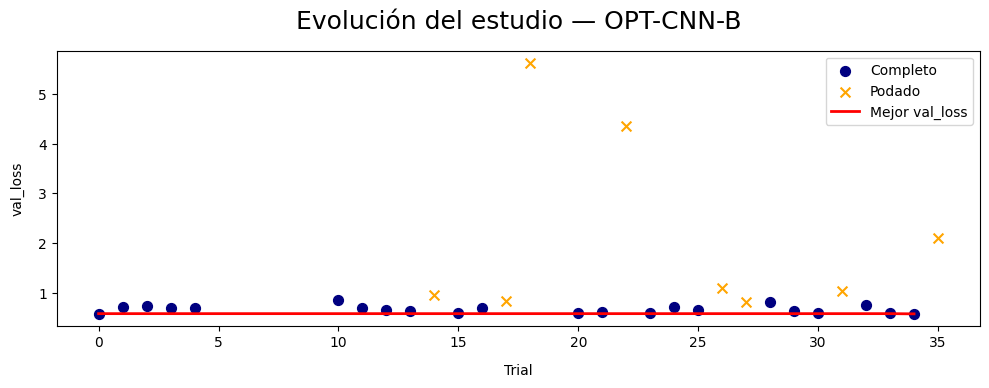

In [11]:
complete = [t for t in study.trials if t.state == TrialState.COMPLETE]
pruned   = [t for t in study.trials if t.state == TrialState.PRUNED]

fig, ax = plt.subplots(figsize=(10, 4))

if complete:
    ax.scatter([t.number for t in complete], [t.value for t in complete],
                color='navy', s=50, label='Completo')

if pruned:
    pruned_y = [list(t.intermediate_values.values())[-1] if t.intermediate_values else None
                for t in pruned]
    ax.scatter([t.number for t in pruned], pruned_y,
                color='orange', s=50, marker='x', label='Podado')

if complete:
    sorted_complete = sorted(complete, key=lambda t: t.number)
    best_so_far = pd.Series([t.value for t in sorted_complete]).cummin()
    ax.plot([t.number for t in sorted_complete], best_so_far,
            color='red', linewidth=2, label='Mejor val_loss')

ax.set_xlabel('Trial', labelpad=10)
ax.set_ylabel('val_loss', labelpad=10)
ax.set_title(f'Evolución del estudio — {EXPERIMENT_NAME}', fontsize=18, y=1.05)
ax.legend()
plt.tight_layout()
plt.show()

### **Análisis por Hiperparámetro**

In [12]:
try:
    import plotly
    fig = optuna.visualization.plot_param_importances(study)
    fig.update_traces(marker_color='navy')
    fig.update_layout(title=f'Importancia de hiperparámetros — {EXPERIMENT_NAME}')
    fig.show()
except ImportError:
    print('plotly no instalado — instalar con: pip install plotly')

/tmp/ipykernel_1261933/3344312118.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax_left.boxplot(
/tmp/ipykernel_1261933/3344312118.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax_left.boxplot(


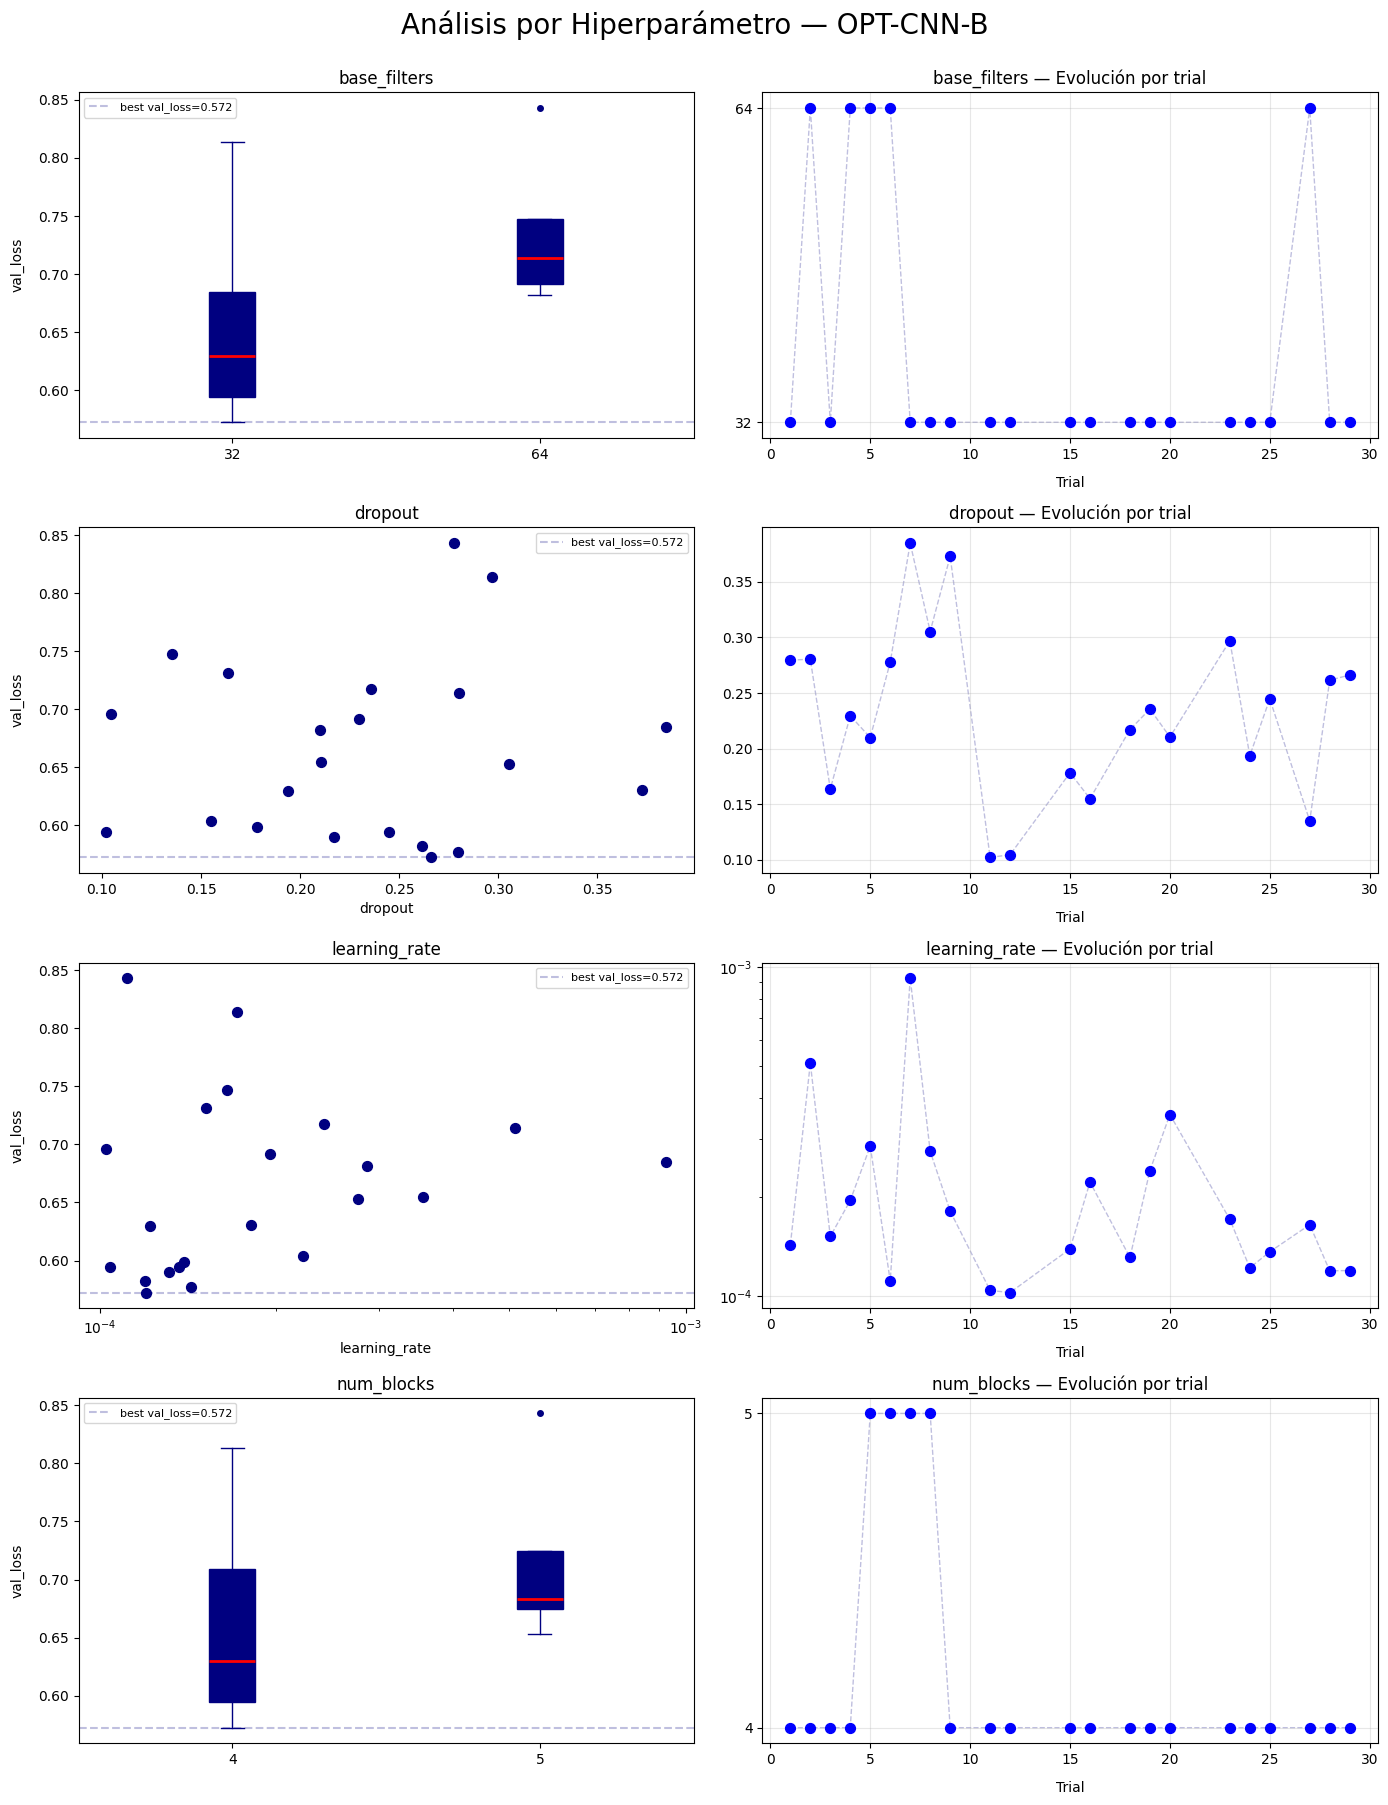

In [13]:
df_complete = df_trials[df_trials['state'] == 'COMPLETE'].copy()
df_complete['number'] = df_complete.index

n_params = len(param_cols)
fig, axes = plt.subplots(n_params, 2, figsize=(14, 4.5 * n_params))
if n_params == 1:
    axes = axes.reshape(1, 2)

for i, param in enumerate(param_cols):
    ax_left  = axes[i, 0]
    ax_right = axes[i, 1]

    is_cat = df_complete[param].dtype == object or df_complete[param].nunique() <= 6

    if is_cat:
        groups = sorted(df_complete[param].dropna().unique())
        data   = [df_complete[df_complete[param] == g]['value'].values for g in groups]
        ax_left.boxplot(
            data, labels=[str(g) for g in groups], patch_artist=True,
            boxprops    = dict(facecolor='navy', color='navy'),
            medianprops = dict(color='red', linewidth=2),
            whiskerprops= dict(color='navy'),
            capprops    = dict(color='navy'),
            flierprops  = dict(markerfacecolor='navy', markeredgecolor='navy', marker='o', markersize=4),
        )
    else:
        ax_left.scatter(df_complete[param], df_complete['value'], color='navy', s=50)
        if param == 'learning_rate':
            ax_left.set_xscale('log')
        ax_left.set_xlabel(param)

    ax_left.axhline(study.best_value, color='navy', linestyle='--', alpha=0.25, linewidth=1.5,
                    label=f'best val_loss={study.best_value:.3f}')
    ax_left.set_ylabel('val_loss', labelpad=10)
    ax_left.set_title(param)
    ax_left.legend(fontsize=8)

    df_sorted = df_complete.sort_values('number')
    if is_cat:
        cats    = sorted(df_complete[param].dropna().unique())
        cat_map = {c: j for j, c in enumerate(cats)}
        y_vals  = df_sorted[param].map(cat_map)
        ax_right.plot(df_sorted['number'], y_vals, color='navy', alpha=0.25, linewidth=1, linestyle='--', zorder=1)
        ax_right.scatter(df_sorted['number'], y_vals, color='blue', s=50, zorder=2)
        ax_right.set_yticks(range(len(cats)))
        ax_right.set_yticklabels(cats)
    else:
        ax_right.plot(df_sorted['number'], df_sorted[param], color='navy', alpha=0.25, linewidth=1, linestyle='--', zorder=1)
        ax_right.scatter(df_sorted['number'], df_sorted[param], color='blue', s=50, zorder=2)
        if param == 'learning_rate':
            ax_right.set_yscale('log')

    ax_right.set_xlabel('Trial', labelpad=10)
    ax_right.set_title(f'{param} — Evolución por trial')
    ax_right.grid(True, alpha=0.3)

plt.suptitle(f'Análisis por Hiperparámetro — {EXPERIMENT_NAME}', fontsize=20, y=1)
plt.tight_layout()
plt.show()

### **Combinación de Hiperparámetros**

In [14]:
try:
    import plotly
    fig = optuna.visualization.plot_parallel_coordinate(study)
    fig.update_layout(title=f'Combinación de Hiperparámetros — {EXPERIMENT_NAME}')
    fig.show()
except ImportError:
    print('plotly no instalado')

In [15]:
df_ranked = df_trials[df_trials['state'].isin(['COMPLETE', 'PRUNED'])].sort_values('value')
display(df_ranked.style.format(fmt, na_rep='-'))

,value,state,t_start,t_finish,duration,epochs_trained,base_filters,dropout,learning_rate,num_blocks
trial,,,,,,,,,,
29,0.5725,COMPLETE,16/08 - 06:23,16/08 - 10:20,03:57:40,39.000000,32,0.2662,1.20e-04,4
1,0.5768,COMPLETE,11/08 - 15:45,11/08 - 20:31,04:45:24,45.000000,32,0.2796,1.43e-04,4
28,0.5827,COMPLETE,16/08 - 03:26,16/08 - 06:23,02:56:35,29.000000,32,0.2615,1.20e-04,4
18,0.5899,COMPLETE,15/08 - 04:47,15/08 - 08:57,04:10:16,41.000000,32,0.2171,1.31e-04,4
11,0.5941,COMPLETE,14/08 - 07:58,14/08 - 12:12,04:14:08,40.000000,32,0.1023,1.04e-04,4
25,0.5944,COMPLETE,15/08 - 19:17,15/08 - 23:15,03:57:31,39.000000,32,0.2447,1.37e-04,4
15,0.5987,COMPLETE,14/08 - 19:55,15/08 - 00:55,04:59:56,48.000000,32,0.1783,1.39e-04,4
16,0.6041,COMPLETE,15/08 - 00:55,15/08 - 03:40,02:44:46,27.000000,32,0.1550,2.22e-04,4
24,0.6296,COMPLETE,15/08 - 17:22,15/08 - 19:17,01:55:55,19.000000,32,0.1937,1.22e-04,4
